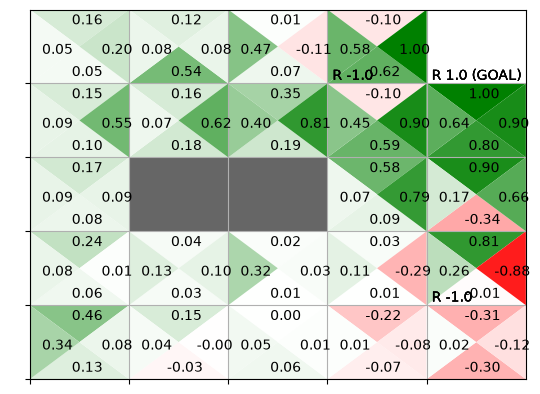

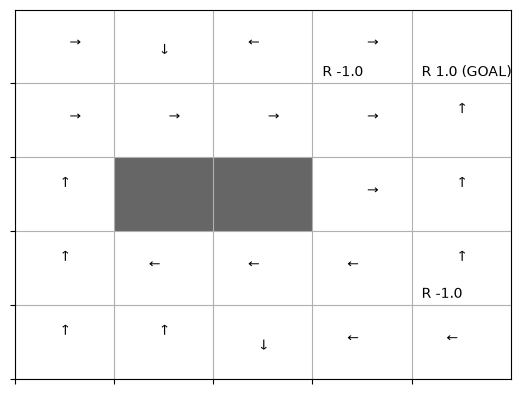

In [3]:
import os, sys; 
sys.path.append(os.pardir)  # for importing the parent dirs
from collections import defaultdict, deque
import numpy as np
from common.gridworld import GridWorld
from common.utils import greedy_probs


class SarsaAgent:
    def __init__(self):
        self.gamma = 0.9
        self.alpha = 0.8
        self.epsilon = 0.1
        self.action_size = 4

        random_actions = {0: 0.25, 1: 0.25, 2: 0.25, 3: 0.25}
        self.pi = defaultdict(lambda: random_actions)
        self.Q = defaultdict(lambda: 0)
        self.memory = deque(maxlen=2)  # deque 사용

    def get_action(self, state):
        action_probs = self.pi[state]  # pi에서 선택
        actions = list(action_probs.keys())
        probs = list(action_probs.values())
        return np.random.choice(actions, p=probs)

    def reset(self):
        self.memory.clear()

    def update(self, state, action, reward, done):
        self.memory.append((state, action, reward, done))
        if len(self.memory) < 2:
            return

        state, action, reward, done = self.memory[0]
        next_state, next_action, _, _ = self.memory[1]
        next_q = 0 if done else self.Q[next_state, next_action]  # 다음 Q 함수

        # TD법으로 self.Q 갱신
        target = reward + self.gamma * next_q
        self.Q[state, action] += (target - self.Q[state, action]) * self.alpha
        
        # 정책 개선
        self.pi[state] = greedy_probs(self.Q, state, self.epsilon)


env = GridWorld()
agent = SarsaAgent()

episodes = 10000
for episode in range(episodes):
    state = env.reset()
    agent.reset()

    while True:
        action = agent.get_action(state)
        next_state, reward, done = env.step(action)

        agent.update(state, action, reward, done)  # 매번 호출

        if done:
            # 목표에 도달했을 때도 호출
            agent.update(next_state, None, None, None)
            break
        state = next_state

# [그림 6-7] SARSA로 얻은 결과
env.render_q(agent.Q)